# Subaperture decomposition of a Sentinel-1 wave-mode imagette

Step-by-step demo of the preprocessing of Ristea et al. (2022), *Guided deep learning by subaperture decomposition: ocean patterns from SAR imagery* ([arXiv:2204.04438](https://arxiv.org/abs/2204.04438)), using the `subaperture` package. `decompose.py` runs the same pipeline from the command line.

Input: one VV imagette of the Sentinel-1C WV SLC product `S1C_WV_SLC__1SSV_20250907T201714_20250907T202352_004023_007FFA_3CF9`, placed in `data/` (see README).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from subaperture.calibration import cmod5n_reference, normalize_slc, sigma0, to_db
from subaperture.decomposition import (azimuth_frequencies, azimuth_spectrum, compensate_hamming,
                                       decimate, decompose, mean_filter, subaperture_windows)
from subaperture.sentinel1 import (product_paths, read_azimuth_time_interval, read_incidence_angle,
                                   read_sigma0_lut, read_slc)

SAFE = Path("../data/S1C_WV_SLC__1SSV_20250907T201714_20250907T202352_004023_007FFA_3CF9.SAFE")
IMAGE_ID = "s1c-wv1-slc-vv-20250907t201714-20250907t201717-004023-007ffa-001"


def show(ax, image, title):
    """Display an intensity image in dB with a 2-98 % stretch."""
    image_db = to_db(image)
    vmin, vmax = np.percentile(image_db, (2, 98))
    ax.imshow(image_db, vmin=vmin, vmax=vmax, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

## 1. Read the SLC, the calibration LUT and the incidence angle

In [2]:
paths = product_paths(SAFE, IMAGE_ID)
slc = read_slc(paths["measurement"])
lut = read_sigma0_lut(paths["calibration"], slc.shape)
incidence = read_incidence_angle(paths["annotation"], slc.shape)
print("SLC shape (azimuth, range):", slc.shape, slc.dtype)
print(f"Incidence angle: {incidence.min():.2f} to {incidence.max():.2f} deg")

SLC shape (azimuth, range): (4918, 5681) complex64
Incidence angle: 23.31 to 24.94 deg


## 2. Sigma0 calibration and CMOD5.N normalisation

sigma0 = |DN|^2 / A_sigma^2, then divided by the CMOD5.N sigma0 of a 10 m/s wind at 45 degrees from the radar look direction. The ratio is the sea surface roughness (SSR). The normalisation is applied to the complex signal so that the azimuth FFT keeps the phase.

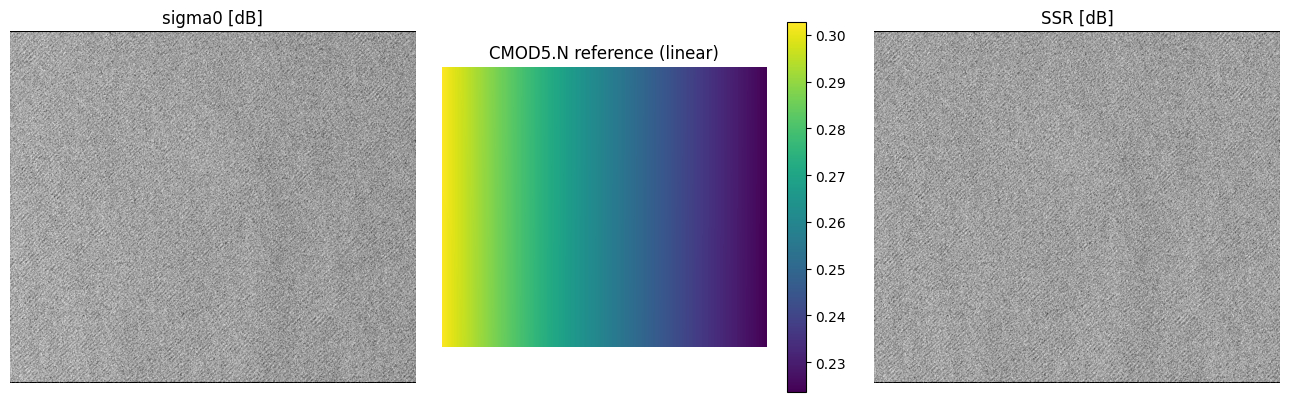

In [3]:
reference = cmod5n_reference(incidence, wind_speed=10.0, wind_direction=45.0)
slc_norm = normalize_slc(slc, lut, reference)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
show(axes[0], decimate(sigma0(slc, lut), 4), "sigma0 [dB]")
im = axes[1].imshow(reference[::4, ::4], cmap="viridis")
axes[1].set_title("CMOD5.N reference (linear)")
axes[1].axis("off")
fig.colorbar(im, ax=axes[1])
show(axes[2], decimate(np.abs(slc_norm) ** 2, 4), "SSR [dB]")
plt.tight_layout()
plt.show()
del slc, lut, reference

## 3. Azimuth FFT and Hamming window compensation (coefficient 0.75)

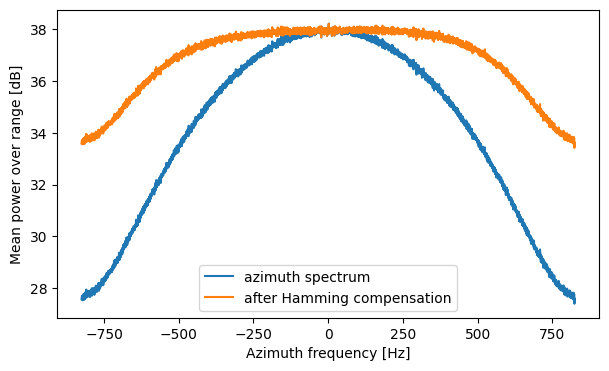

In [4]:
spectrum = azimuth_spectrum(slc_norm)
compensated = compensate_hamming(spectrum, alpha=0.75)
freqs = azimuth_frequencies(slc_norm.shape[0], read_azimuth_time_interval(paths["annotation"]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(freqs, to_db(np.mean(np.abs(spectrum) ** 2, axis=1)), label="azimuth spectrum")
ax.plot(freqs, to_db(np.mean(np.abs(compensated) ** 2, axis=1)), label="after Hamming compensation")
ax.set_xlabel("Azimuth frequency [Hz]")
ax.set_ylabel("Mean power over range [dB]")
ax.legend()
plt.show()
del spectrum

## 4. Four shifted Hamming windows (coefficient 0.75)

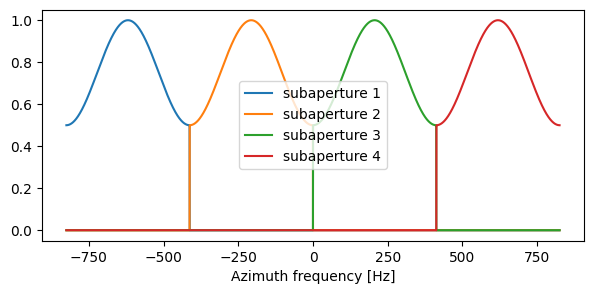

In [5]:
windows = subaperture_windows(slc_norm.shape[0], n_looks=4, alpha=0.75)
fig, ax = plt.subplots(figsize=(7, 3))
for k, w in enumerate(windows):
    ax.plot(freqs, w, label=f"subaperture {k + 1}")
ax.set_xlabel("Azimuth frequency [Hz]")
ax.legend()
plt.show()
del compensated

## 5. Azimuth iFFT, intensity, 10 x 10 mean filter and decimation by 10

Subaperture stack: (4, 492, 569)


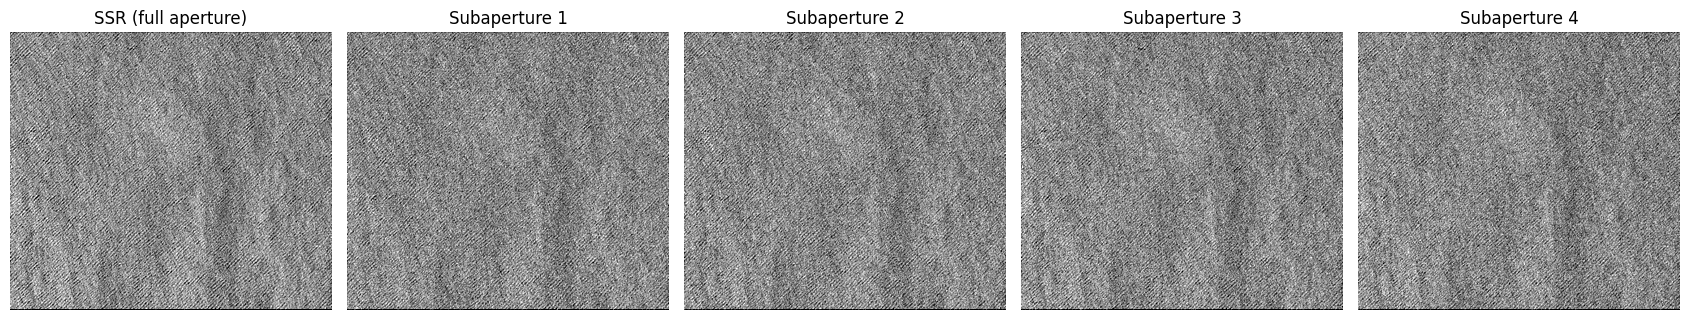

In [6]:
looks = decompose(slc_norm, n_looks=4, alpha=0.75, filter_size=10, factor=10)
ssr = decimate(mean_filter(np.abs(slc_norm) ** 2, 10), 10)
print("Subaperture stack:", looks.shape)

fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
show(axes[0], ssr, "SSR (full aperture)")
for k, look in enumerate(looks):
    show(axes[k + 1], look, f"Subaperture {k + 1}")
plt.tight_layout()
plt.show()